# What skills do data roles actually demand?

End-to-end answer from the pipeline: Adzuna + Remotive postings → cleaned `jobs` table → dictionary skill extraction (`skill_hits`). This notebook ranks skills by **share of postings** that mention them and plots the top of that ranking.

The denominator is **distinct jobs**, not raw rows: the same job recurs across overlapping role queries (different ids, same company+title) and can appear on more than one source, so we collapse on the cross-source `dedup_key` (normalized company+title) before counting. Rows with no key (missing company/title) stay individually counted.

In [1]:
import sqlite3
import sys
from pathlib import Path

import pandas as pd

# The notebook lives in notebooks/; the jobskills package sits one level up at
# the repo root. Put that root on sys.path so `import jobskills` resolves no
# matter where Jupyter was launched from.
REPO_ROOT = Path.cwd().parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from jobskills import config

# Pull the two analysis tables into pandas. skill_hits is one row per
# (posting, skill); jobs is one row per posting — we need both because the
# demand *share* divides hits by the distinct-job count.
with sqlite3.connect(config.SQLITE_PATH) as conn:
    hits = pd.read_sql_query("SELECT posting_id, skill, category FROM skill_hits", conn)
    jobs = pd.read_sql_query("SELECT id, dedup_key, source FROM jobs", conn)

# Job identity for de-duplication: the cross-source dedup_key (normalized
# company+title) where present, else a per-id token so key-less rows (missing
# company/title) each stay a distinct job rather than collapsing into one bucket.
jobs["ident"] = jobs["dedup_key"].where(jobs["dedup_key"].notna(), "id:" + jobs["id"].astype(str))

n_postings = jobs["ident"].nunique()  # distinct jobs after collapsing dupes
print(f"{len(hits)} skill hits across {len(jobs)} rows -> {n_postings} distinct jobs")
hits.head()

1014 skill hits across 1423 rows -> 1189 distinct jobs


,posting_id,skill,category
0,5574048694,power bi,bi_tools
1,5574048689,power bi,bi_tools
2,5574048686,power bi,bi_tools
3,5574048688,power bi,bi_tools
4,5574048685,power bi,bi_tools


In [2]:
# Attach each hit's job identity, then count DISTINCT jobs per skill. A skill is
# credited once per job even if the job's duplicate rows (same company+title under
# several role queries) all matched it — counting rows here would re-inflate the
# very dupes the dedup_key collapses. Inner join drops the 48 key-less rows only
# where they have no hits; key-less rows that DO match keep their per-id ident.
m = hits.merge(jobs[["id", "ident"]], left_on="posting_id", right_on="id")
demand = m.groupby("skill")["ident"].nunique().sort_values(ascending=False)

# Share of ALL distinct jobs (denominator = every distinct job, not just the
# matched subset), as a percent — comparison-ready as snapshots change size.
demand = demand.rename("postings").to_frame()
demand["share_pct"] = demand["postings"] / n_postings * 100

demand.head(10)

,postings,share_pct
skill,,
ai,262,22.035324
machine learning,107,8.999159
sql,43,3.616484
power bi,36,3.027754
python,29,2.439024
aws,24,2.018503
databricks,20,1.682086
r,20,1.682086
azure,20,1.682086


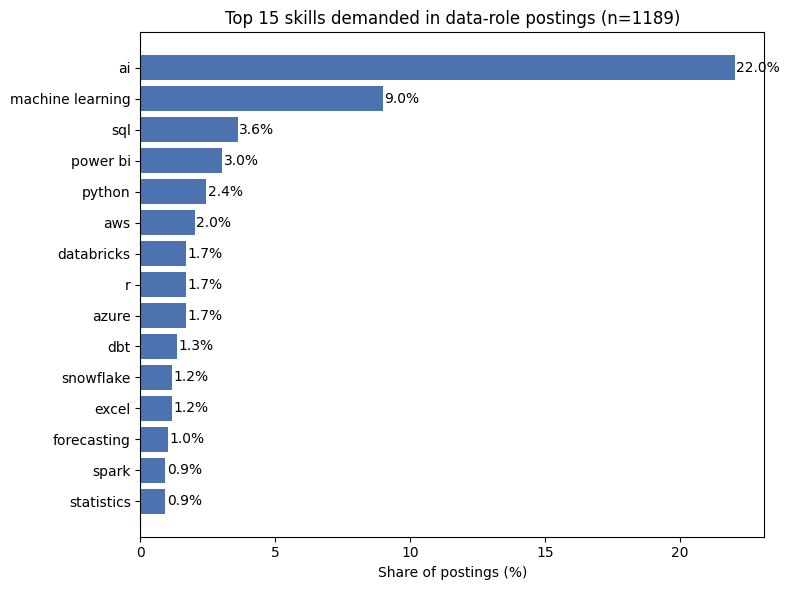

In [3]:
import matplotlib.pyplot as plt

TOP_N = 15
top = demand.head(TOP_N)  # already sorted desc by value_counts()

fig, ax = plt.subplots(figsize=(8, 6))

# Drive bars + text off numeric y-positions, not the skill strings. ax.text at
# a *string* y-position trips matplotlib's category converter (returns a 1-elem
# array -> float() error), so we place everything at integers 0..N-1 and hang
# the skill names on the ticks instead.
y_pos = range(len(top))
ax.barh(list(y_pos), top["share_pct"], color="#4C72B0")
ax.set_yticks(list(y_pos))
ax.set_yticklabels(top.index)

# barh draws position 0 at the BOTTOM; invert so the ranking reads top-down.
ax.invert_yaxis()

ax.set_xlabel("Share of postings (%)")
ax.set_title(f"Top {TOP_N} skills demanded in data-role postings (n={n_postings})")

# Label each bar with its exact percentage so the reader needn't eyeball the axis.
for y, share in zip(y_pos, top["share_pct"]):
    ax.text(share + 0.05, y, f"{share:.1f}%", va="center")

fig.tight_layout()
plt.show()


## What this first cut shows

**Question:** across continental-European data-role postings (Germany, Switzerland, Spain via Adzuna + a global remote board via Remotive — data analyst, data scientist, BI analyst, analytics engineer, BI developer), which skills are asked for most often?

**Read:** of **1,189 distinct jobs** (Adzuna DE 561 / ES 426 / CH 169, Remotive remote 33), the most-demanded skills are **machine learning, SQL, Power BI, and Python**, followed by cloud/warehouse tooling (AWS, Databricks, Azure, Snowflake, dbt). The ranking is by *share of distinct jobs* — the percent whose title or description mentions the skill — so it stays comparable when later snapshots scrape a different number of postings.

**Dedup matters:** collapsing rows on an exact `company+title` key turned 1,423 rows into 1,189 distinct jobs. The drop isn't cross-source overlap (DE/CH/ES vs global remote don't intersect — **0** cross-source collisions this snapshot) — it's the *same Adzuna job recurring under overlapping role queries* with different ids, which `UNIQUE(id)` couldn't catch. That double-counting had inflated M1's shares by ~30–40% (e.g. machine learning 11.1% → 8.8%, SQL 5.8% → 3.6%). *Caveat:* exact-match can over-collapse two genuinely separate openings that share a generic title at one big employer; fuzzy/role-aware dedup is deferred.

**Honest caveat — two compounding gaps, now sharper:** only ~25% of jobs matched *any* taxonomy skill. Remotive's full English-language descriptions match at **76%**, against Adzuna **CH 36% / DE 20% / ES 22%** — which cleanly separates the two gaps: a **coverage gap** (the hand-curated `skills.yaml` doesn't yet know every term) and a **language gap** (an English-only taxonomy under-matches German/Spanish text, and Adzuna's 500-char truncation starves the rest). The distinct-job denominator keeps the percentages truthful rather than inflating them off the matched subset. Closing both gaps is M3 work — n-gram mining for coverage, German/Spanish aliases for language.

*Adzuna + Remotive single snapshot; a starting baseline, not a final read on the market. Remotive's employment tag (25 full / 4 part / 3 contract / 2 freelance) fills the part-time/full-time column Adzuna left empty — the input the M3 part-time-vs-full-time comparison needs.*